# Classificador de Lixo Reciclável com Redes Neurais

**Disciplina:** Redes Neurais  |  **Turma:** 6º Periodo  |  **Data:** 02/12/2026

**Integrantes:**
- Wlademir Pontes Xavier
- Celso
- João
- Daniel

**Declaração de uso de IA:** a estrutura inicial deste notebook foi gerada com apoio do Claude (Anthropic). A equipe executou todas as células, interpretou os resultados e é capaz de explicar cada etapa. PREENCHER: o que o grupo alterou, escreveu ou testou por conta própria.

---

### Como usar
1. No Colab: **Ambiente de execução > Alterar tipo de ambiente de execução > GPU**. Funciona sem GPU, só fica mais lento.
2. Rode as células **em ordem**, lendo os textos entre elas.

### Mapa: etapa do notebook x slide da apresentação
| Etapa | Assunto | Slides |
|---|---|---|
| 1 | Problema e objetivo | 2 e 3 |
| 2 | Conjunto de dados | 4 |
| 3 | Preparação e separação dos dados | 5 |
| 4 | Baseline | 6 |
| 5 | Representação dos dados | 7 |
| 6 | Arquitetura e funções | 8 e 9 |
| 7 | Treinamento | 10 |
| 8 | Resultados e comparação | 11 e 12 |
| 9 | Acertos e erros | 13 |
| 10 | Limitações e ética | 14 |
| 11 | Demonstração | 15 |

## Etapa 1: Problema e objetivo (slides 2 e 3)

- **Problema:** separar o lixo corretamente é o primeiro passo da reciclagem, e muita gente erra a categoria do material. Descartar errado contamina o material reciclável.
- **Entrada:** uma foto do objeto (imagem colorida).
- **Saída:** uma das 6 classes (`cardboard` papelão, `glass` vidro, `metal`, `paper` papel, `plastic` plástico, `trash` rejeito) e a confiança do modelo.
- **Tipo de tarefa:** **classificação multiclasse** (visão computacional).
- **Quem poderia usar:** aplicativos de educação ambiental, escolas, lixeiras inteligentes e cooperativas de reciclagem, sempre como apoio e não como decisão final.
- **Objetivo geral:** construir um protótipo que classifica a foto de um objeto em 6 categorias de material, usando uma rede neural pré-treinada.
- **Resultado esperado:** a rede superar com folga as baselines simples, medido pelo F1 macro.

In [1]:
import os, glob, hashlib, time, random, subprocess, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, accuracy_score, f1_score)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42  # semente fixa: os resultados ficam reproduzíveis
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU disponível:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU disponível: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Etapa 2: Conjunto de dados (slide 4)

- **Nome:** TrashNet (Thung e Yang, Stanford, 2016), versão redimensionada.
- **Fontes:** https://github.com/garythung/trashnet e https://huggingface.co/datasets/garythung/trashnet (licença MIT).
- **Conteúdo:** fotos de objetos em 6 classes: vidro, papel, papelão, plástico, metal e rejeito.
- **Formato:** imagens coloridas (JPG), uma pasta por classe.
- **Citação:** Thung, G. e Yang, M. (2016). *Classification of Trash for Recyclability Status*. Stanford CS229.

A célula abaixo baixa o arquivo zip. Se o Hugging Face falhar, ela tenta o GitHub.

In [2]:
DATA_DIR = "trashnet_data"

if not os.path.exists(DATA_DIR):
    try:
        from huggingface_hub import hf_hub_download
        zip_path = hf_hub_download(repo_id="garythung/trashnet",
                                   filename="dataset-resized.zip",
                                   repo_type="dataset")
    except Exception as e:
        print("Não consegui pelo Hugging Face, tentando pelo GitHub...", e)
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/garythung/trashnet", "trashnet_repo"], check=True)
        zip_path = "trashnet_repo/data/dataset-resized.zip"
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_DIR)

print("Dados prontos em:", DATA_DIR)

dataset-resized.zip: reconstructing file:   0%|          |  0.00B / 42.8MB            

dataset-resized.zip: downloading bytes:           |  0.00B            

Dados prontos em: trashnet_data


In [3]:
# Lista todas as imagens e usa o nome da pasta como classe
EXTENSOES = (".jpg", ".jpeg", ".png")
caminhos = [p for p in glob.glob(f"{DATA_DIR}/**/*", recursive=True)
            if p.lower().endswith(EXTENSOES)
            and "__MACOSX" not in p
            and not os.path.basename(p).startswith("._")]

df = pd.DataFrame({"caminho": caminhos})
df["classe"] = df["caminho"].apply(lambda p: os.path.basename(os.path.dirname(p)))

print("Total de imagens:", len(df))
print(df["classe"].value_counts())
df.head()

Total de imagens: 2527
classe
paper        594
glass        501
plastic      482
metal        410
cardboard    403
trash        137
Name: count, dtype: int64


,caminho,classe
0,trashnet_data/dataset-resized/cardboard/cardbo...,cardboard
1,trashnet_data/dataset-resized/cardboard/cardbo...,cardboard
2,trashnet_data/dataset-resized/cardboard/cardbo...,cardboard
3,trashnet_data/dataset-resized/cardboard/cardbo...,cardboard
4,trashnet_data/dataset-resized/cardboard/cardbo...,cardboard


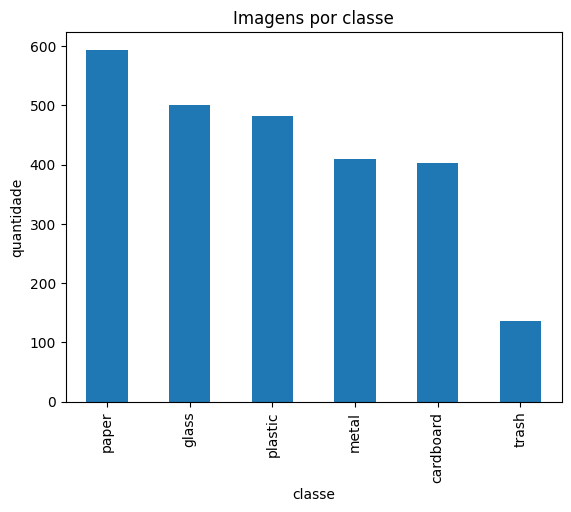

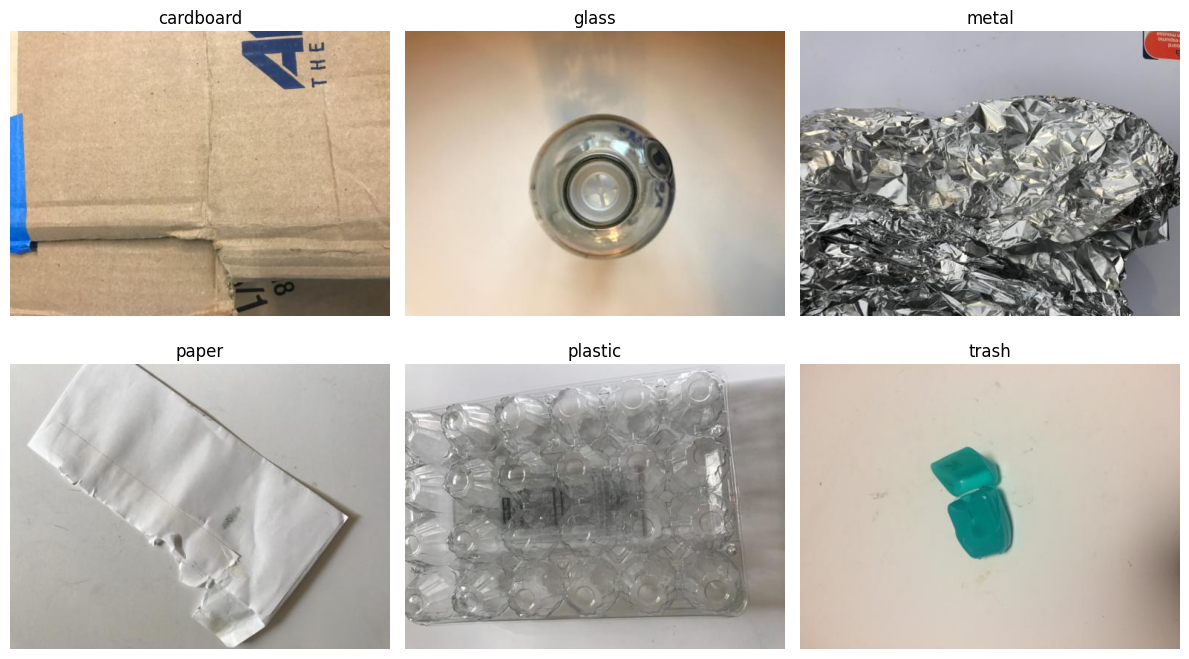

In [4]:
# Distribuição das classes e um exemplo de cada uma
df["classe"].value_counts().plot(kind="bar", title="Imagens por classe", ylabel="quantidade")
plt.show()

classes_visual = sorted(df["classe"].unique())
fig, axs = plt.subplots(2, 3, figsize=(12, 7))
for ax, c in zip(axs.ravel(), classes_visual):
    exemplo = df[df["classe"] == c].sample(1, random_state=SEED)["caminho"].iloc[0]
    ax.imshow(Image.open(exemplo)); ax.set_title(c); ax.axis("off")
plt.tight_layout(); plt.show()

**Problemas encontrados nos dados:**
- **Desbalanceamento:** `paper` tem 594 imagens e `trash` apenas 137 (cerca de 4 vezes menos). Por isso a acurácia sozinha engana e usamos o **F1 macro**, que dá o mesmo peso a todas as classes.
- **Duplicatas:** 3 arquivos repetidos, removidos na Etapa 3. Nenhuma imagem corrompida.
- **Dataset pequeno:** 2.527 imagens originais (2.524 após a limpeza) para 6 classes.
- **Condições controladas:** as fotos do TrashNet mostram objetos isolados, em ambiente padronizado. O modelo pode ir pior com fotos reais de celular, com outro fundo e outra luz (testado na demonstração, Etapa 11).

## Etapa 3: Preparação e separação dos dados (slide 5)

O que fazemos antes de treinar:
1. **Remover duplicatas** (arquivos idênticos, comparados por hash MD5).
2. **Verificar imagens corrompidas**.
3. **Separar treino (70%), validação (15%) e teste (15%)** de forma estratificada, isto é, mantendo a proporção de cada classe em cada parte.

**Como evitamos vazamento de dados (data leakage):**
- Separamos os dados **antes** de qualquer outra etapa que "aprenda" algo com eles (normalização do baseline, pesos de classe, treino).
- O `StandardScaler` do baseline é ajustado **só no treino**.
- A augmentação (girar, espelhar) é aplicada **só no treino**.
- O conjunto de **teste** só é usado no final, uma única vez.
- Removemos duplicatas exatas para que a mesma imagem não apareça em treino e teste.

In [5]:
def hash_arquivo(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df["hash"] = df["caminho"].apply(hash_arquivo)
n_antes = len(df)
df = df.drop_duplicates(subset="hash").reset_index(drop=True)
print(f"Duplicatas removidas: {n_antes - len(df)}")

def abre_ok(p):
    try:
        with Image.open(p) as im:
            im.verify()
        return True
    except Exception:
        return False

df["ok"] = df["caminho"].apply(abre_ok)
print("Imagens corrompidas:", (~df["ok"]).sum())
df = df[df["ok"]].drop(columns=["ok"]).reset_index(drop=True)

with Image.open(df["caminho"].iloc[0]) as im:
    print("Tamanho de uma imagem (largura x altura):", im.size)
print("Imagens restantes:", len(df))

Duplicatas removidas: 3
Imagens corrompidas: 0
Tamanho de uma imagem (largura x altura): (512, 384)
Imagens restantes: 2524


In [6]:
classes = sorted(df["classe"].unique())
classe_para_id = {c: i for i, c in enumerate(classes)}
df["y"] = df["classe"].map(classe_para_id)
print("Classes:", classe_para_id)

treino_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["y"], random_state=SEED)
val_df, teste_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["y"], random_state=SEED)

resumo = pd.DataFrame({"treino": treino_df["classe"].value_counts(),
                       "validação": val_df["classe"].value_counts(),
                       "teste": teste_df["classe"].value_counts()})
resumo.loc["TOTAL"] = resumo.sum()
print(resumo)

# Conferência anti-vazamento: nenhum arquivo em mais de um conjunto
assert not (set(treino_df["hash"]) & set(val_df["hash"]))
assert not (set(treino_df["hash"]) & set(teste_df["hash"]))
assert not (set(val_df["hash"]) & set(teste_df["hash"]))
print("OK: nenhum arquivo repetido entre treino, validação e teste.")

Classes: {'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}
           treino  validação  teste
classe                             
paper         416         89     89
glass         350         75     76
plastic       336         72     72
metal         286         62     61
cardboard     282         61     60
trash          96         20     21
TOTAL        1766        379    379
OK: nenhum arquivo repetido entre treino, validação e teste.


**Atenção (limitação):** se o dataset tiver várias fotos parecidas do mesmo objeto, elas podem cair em conjuntos diferentes e deixar o resultado um pouco otimista. A checagem por hash só pega arquivos idênticos. Citem isso no slide de limitações.

## Etapa 4: Baseline (slide 6)

A **baseline** é uma solução simples que serve de régua. Se a rede neural não for melhor que ela, não valeu a pena a complexidade.

Usamos duas:
1. **Classe mais frequente:** sempre responde a classe que mais aparece no treino. Mostra o piso do problema.
2. **Regressão logística sobre pixels:** reduz a imagem para 32x32, vira um vetor de 3072 números e aprende uma fronteira linear entre as classes. Não entende formas nem texturas, só valores de pixel.

**Por que essas duas?** A classe mais frequente é o piso: qualquer modelo útil precisa passar dela. A regressão logística é um modelo simples que enxerga só os valores dos pixels, então mostra quanto a rede ganha ao aprender características da imagem (bordas, texturas, formas) em vez de olhar pixel por pixel.

**Resultados da baseline no conjunto de teste:** classe mais frequente com acurácia 0,235 e F1 macro 0,063; regressão logística com acurácia 0,401 e F1 macro 0,370.

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

TAM_BASELINE = 32

def carrega_pequena(caminhos):
    # imagem -> 32x32x3 -> vetor de 3072 números entre 0 e 1
    return np.stack([
        np.asarray(Image.open(p).convert("RGB").resize((TAM_BASELINE, TAM_BASELINE)),
                   dtype="float32").ravel() / 255.0
        for p in caminhos
    ])

Xb_treino = carrega_pequena(treino_df["caminho"])
Xb_val    = carrega_pequena(val_df["caminho"])
Xb_teste  = carrega_pequena(teste_df["caminho"])
y_treino, y_val, y_teste = treino_df["y"].values, val_df["y"].values, teste_df["y"].values
print("Formato do vetor de cada imagem (baseline):", Xb_treino.shape[1])

def metricas(y_true, y_pred):
    return accuracy_score(y_true, y_pred), f1_score(y_true, y_pred, average="macro")

# Baseline 1: classe mais frequente
dummy = DummyClassifier(strategy="most_frequent").fit(Xb_treino, y_treino)
acc, f1 = metricas(y_val, dummy.predict(Xb_val))
print(f"Baseline 1 (classe mais frequente) | validação: acurácia={acc:.3f}  F1 macro={f1:.3f}")

# Baseline 2: regressão logística (o StandardScaler é ajustado só no treino)
t0 = time.time()
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500))
logreg.fit(Xb_treino, y_treino)  # avisos de convergência podem aparecer e não são problema
acc, f1 = metricas(y_val, logreg.predict(Xb_val))
print(f"Baseline 2 (regressão logística)   | validação: acurácia={acc:.3f}  F1 macro={f1:.3f}  ({time.time()-t0:.0f}s)")

Formato do vetor de cada imagem (baseline): 3072
Baseline 1 (classe mais frequente) | validação: acurácia=0.235  F1 macro=0.063
Baseline 2 (regressão logística)   | validação: acurácia=0.456  F1 macro=0.439  (22s)


## Etapa 5: Representação dos dados (slide 7)

Uma rede neural só entende números. O caminho da imagem até a decisão é:

1. **Pixels:** uma imagem colorida é uma grade de pixels, cada um com 3 valores (vermelho, verde, azul) de 0 a 255.
2. **Tensor:** redimensionamos todas as imagens para 224x224, ficando um tensor de formato `(224, 224, 3)`.
3. **Normalização:** os valores de 0 a 255 são reescalados para o intervalo de -1 a 1, que é o que o MobileNetV2 espera.
4. **Embedding:** as camadas convolucionais do MobileNetV2 transformam a imagem em um vetor de **1280 números** que resume o conteúdo visual (bordas, texturas, formas). É o "significado" da imagem para a rede.
5. A parte final da rede usa esse vetor para decidir a classe.

Na baseline foi mais simples: 32x32x3 = **3072 números** diretamente dos pixels, sem nenhum resumo inteligente.

In [8]:
IMG = 224       # lado da imagem de entrada da rede
BATCH = 32      # tamanho do lote
AUTOTUNE = tf.data.AUTOTUNE

def carrega(caminho, rotulo):
    img = tf.io.read_file(caminho)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG, IMG))   # valores ainda de 0 a 255
    return img, rotulo

def cria_dataset(df_parte, embaralhar=False):
    ds = tf.data.Dataset.from_tensor_slices((df_parte["caminho"].values, df_parte["y"].values))
    if embaralhar:
        ds = ds.shuffle(len(df_parte), seed=SEED)
    return ds.map(carrega, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

ds_treino = cria_dataset(treino_df, embaralhar=True)
ds_val    = cria_dataset(val_df)
ds_teste  = cria_dataset(teste_df)   # sem embaralhar: a ordem bate com teste_df

# Mostra como UMA imagem vira tensor
img_ex, _ = carrega(treino_df["caminho"].iloc[0], 0)
print("Formato do tensor:", img_ex.shape)
print("Valores de pixel: mínimo =", float(tf.reduce_min(img_ex)), "| máximo =", float(tf.reduce_max(img_ex)))

Formato do tensor: (224, 224, 3)
Valores de pixel: mínimo = 55.16838836669922 | máximo = 251.22959899902344


## Etapa 6: Arquitetura e funções (slides 8 e 9)

### Arquitetura: transfer learning com MobileNetV2
O **MobileNetV2** é uma rede convolucional leve, já treinada no ImageNet (mais de 1 milhão de imagens, 1000 categorias). Ela já "sabe ver" bordas, texturas e formas. Em vez de treinar do zero (precisaria de muito mais dados e tempo), **congelamos** a rede e treinamos só uma cabeça nova para as nossas 6 classes.

```
Imagem (224x224x3)
  -> Augmentação (só no treino: espelhar, girar, zoom)
  -> Rescaling (0..255 vira -1..1)
  -> MobileNetV2 congelada  -> mapa de características
  -> GlobalAveragePooling   -> vetor de 1280 números (embedding)
  -> Dropout (30%)
  -> Dense 128 + ReLU
  -> Dense 6 + Softmax      -> probabilidade de cada classe
```

**Por que essa escolha?** O dataset é pequeno (poucos milhares de imagens), e transfer learning funciona bem nesse cenário. **PREENCHER (com as suas palavras, é uma pergunta provável do professor):** o que é uma convolução e por que ela serve para imagens? Dica: pense em um filtro pequeno que desliza pela imagem procurando padrões como bordas e texturas.

**Tamanho do nosso modelo:** 2.422.726 parâmetros no total, dos quais só 164.742 são treinados. Os 2.257.984 da MobileNetV2 ficam congelados.

### Funções e configurações (justifiquem cada uma no slide 9)
- **ReLU** (camada oculta): devolve o valor se for positivo e zero se for negativo. É simples, rápida e ajuda a rede a aprender sem os gradientes sumirem.
- **Softmax** (saída): transforma as 6 saídas em probabilidades que somam 1. É o padrão para **várias classes**.
- **Sparse Categorical Cross-Entropy** (perda): pune forte quando a rede dá pouca probabilidade à classe correta. "Sparse" significa que os rótulos são números inteiros (0 a 5), não vetores one-hot.
- **Adam** (otimizador): ajusta os pesos usando o gradiente, adaptando o passo de cada peso. Funciona bem sem muito ajuste.
- **Dropout 0.3:** desliga 30% dos neurônios aleatoriamente a cada passo do treino, o que reduz o overfitting.
- **Pesos de classe:** a classe `trash` é rara, então erros nela pesam mais no treino.
- **Early stopping:** para o treino quando a perda de validação para de melhorar e devolve os melhores pesos.

In [9]:
augmentacao = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentacao")   # só age durante o treino

base = keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3),
                                      include_top=False, weights="imagenet")
base.trainable = False   # congelada: seus pesos não mudam no treino

entrada = keras.Input(shape=(IMG, IMG, 3))
x = augmentacao(entrada)
x = layers.Rescaling(1 / 127.5, offset=-1)(x)   # 0..255 -> -1..1
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
saida = layers.Dense(len(classes), activation="softmax")(x)

modelo = keras.Model(entrada, saida)
modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
               loss="sparse_categorical_crossentropy",
               metrics=["accuracy"])
modelo.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentacao (Sequential)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Etapa 7: Treinamento (slide 10)

- **Épocas:** até 15, com early stopping (paciência 3).
- **Tamanho do lote:** 32.
- **Modelo pré-treinado:** sim, MobileNetV2 com pesos do ImageNet, congelado.
- **Ajustes:** augmentação, dropout, pesos de classe.

**O que aconteceu na execução:** o treino rodou **8 épocas** (parou antes das 15 pelo early stopping) em cerca de **0,8 minuto** na GPU do Colab. A melhor época foi a 5ª, com perda de validação 0,433 e acurácia de validação 0,852. Os pesos dessa época foram restaurados.

In [10]:
from sklearn.utils.class_weight import compute_class_weight

pesos = compute_class_weight("balanced", classes=np.arange(len(classes)), y=y_treino)
class_weight = {i: float(p) for i, p in enumerate(pesos)}
print("Pesos de classe:", {classes[i]: round(p, 2) for i, p in class_weight.items()})

EPOCAS = 15
callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                           restore_best_weights=True)]

t0 = time.time()
historico = modelo.fit(ds_treino, validation_data=ds_val, epochs=EPOCAS,
                       class_weight=class_weight, callbacks=callbacks)
tempo_treino = time.time() - t0
print(f"Tempo de treino: {tempo_treino/60:.1f} min | épocas executadas: {len(historico.history['loss'])}")

Pesos de classe: {'cardboard': 1.04, 'glass': 0.84, 'metal': 1.03, 'paper': 0.71, 'plastic': 0.88, 'trash': 3.07}
Epoch 1/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 19s 142ms/step - accuracy: 0.5776 - loss: 1.1519 - val_accuracy: 0.7784 - val_loss: 0.5956
Epoch 2/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 68ms/step - accuracy: 0.7911 - loss: 0.6090 - val_accuracy: 0.7836 - val_loss: 0.5851
Epoch 3/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step - accuracy: 0.8018 - loss: 0.5475 - val_accuracy: 0.8285 - val_loss: 0.4851
Epoch 4/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 94ms/step - accuracy: 0.8386 - loss: 0.4596 - val_accuracy: 0.8074 - val_loss: 0.5045
Epoch 5/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - accuracy: 0.8409 - loss: 0.4394 - val_accuracy: 0.8522 - val_loss: 0.4328
Epoch 6/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - accuracy: 0.8675 - loss: 0.3702 - val_accuracy: 0.8338 - val_loss: 0.4788
Epoch 7/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 82ms/step - accuracy: 0.8584 - loss: 0.3923 - val_accuracy: 0.8127 - val_loss: 0.

In [ ]:
h = historico.history
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(h["loss"], label="treino"); axs[0].plot(h["val_loss"], label="validação")
axs[0].set_title("Perda"); axs[0].set_xlabel("época"); axs[0].legend()
axs[1].plot(h["accuracy"], label="treino"); axs[1].plot(h["val_accuracy"], label="validação")
axs[1].set_title("Acurácia"); axs[1].set_xlabel("época"); axs[1].legend()
plt.tight_layout(); plt.show()

**Como ler os gráficos:**
- Se a perda de treino cai e a de validação sobe, é **overfitting** (a rede decorou o treino).
- Se as duas ficam altas, é **underfitting** (a rede ainda não aprendeu).
- Treino abaixo da validação pode acontecer aqui, porque a augmentação e o dropout só atuam no treino.

**O que vimos neste treino** (confirmem no gráfico depois de rodar a célula acima):
- A perda de treino caiu de 1,15 para 0,35 ao longo das 8 épocas. A de validação caiu de 0,60 para cerca de 0,44 e oscilou depois da 5ª época.
- A acurácia final foi 0,87 no treino e 0,84 na validação. A diferença é pequena, então não há sinal forte de overfitting.
- A validação oscila (0,85 na época 5 e 0,81 na 7) porque o conjunto de validação é pequeno (379 imagens).

## Etapa 8: Resultados e comparação com a baseline (slides 11 e 12)

**Métricas escolhidas:**
- **F1 macro (principal):** média do F1 de cada classe, tratando todas com o mesmo peso. Como as classes são desbalanceadas, é mais honesta que a acurácia.
- **Acurácia:** fácil de entender, mas pode esconder um desempenho ruim na classe rara.
- **Precisão e recall por classe:** mostram se o modelo erra por "ver demais" ou "ver de menos" cada classe.
- **Matriz de confusão:** mostra exatamente quais classes são confundidas.

Aqui o conjunto de **teste** é usado pela primeira vez.

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step
              precision    recall  f1-score   support

   cardboard      0.898     0.883     0.891        60
       glass      0.773     0.895     0.829        76
       metal      0.845     0.803     0.824        61
       paper      0.907     0.876     0.891        89
     plastic      0.812     0.778     0.794        72
       trash      0.579     0.524     0.550        21

    accuracy                          0.831       379
   macro avg      0.802     0.793     0.797       379
weighted avg      0.832     0.831     0.831       379



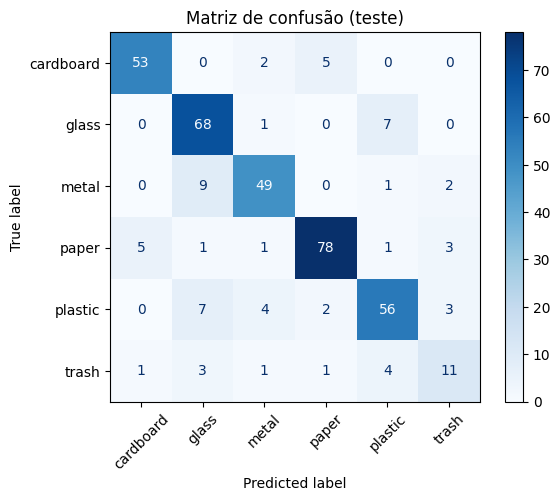

In [16]:
probs = modelo.predict(ds_teste)
y_pred = probs.argmax(axis=1)
y_true = y_teste

print(classification_report(y_true, y_pred, target_names=classes, digits=3))

ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=classes,
                                        xticks_rotation=45, cmap="Blues")
plt.title("Matriz de confusão (teste)"); plt.show()

In [12]:
linhas = []
comparacao = [
    ("Baseline 1: classe mais frequente", dummy.predict(Xb_teste)),
    ("Baseline 2: regressão logística (pixels 32x32)", logreg.predict(Xb_teste)),
    ("Rede neural (MobileNetV2 + camadas novas)", y_pred),
]
for nome, pred in comparacao:
    acc, f1 = metricas(y_teste, pred)
    linhas.append({"Modelo": nome, "Métrica principal": "F1 macro",
                   "F1 macro": round(f1, 3), "Acurácia": round(acc, 3)})

tabela = pd.DataFrame(linhas)
tabela

,Modelo,Métrica principal,F1 macro,Acurácia
0,Baseline 1: classe mais frequente,F1 macro,0.063,0.235
1,Baseline 2: regressão logística (pixels 32x32),F1 macro,0.370,0.401
2,Rede neural (MobileNetV2 + camadas novas),F1 macro,0.797,0.831


**Respostas para o slide 12:**
- **A rede superou a baseline?** Sim. F1 macro de 0,797 contra 0,370 da regressão logística e 0,063 da classe mais frequente. Acurácia de 0,831 contra 0,401 e 0,235.
- **A diferença foi relevante?** Sim. O F1 foi mais que o dobro do da melhor baseline, uma diferença grande o bastante para não ser atribuída só ao acaso.
- **O custo adicional se justificou?** Sim. A rede é bem mais complexa (2,4 milhões de parâmetros), mas treina em menos de 1 minuto na GPU porque aproveita um modelo pré-treinado. O custo extra é pequeno para o ganho.
- **Qual solução usar na prática?** A rede neural, com as ressalvas da Etapa 10 e com revisão humana.

**Por classe:** `cardboard` e `paper` foram as melhores (F1 0,891 cada). `trash` foi a pior (F1 0,550, com apenas 21 imagens no teste), o que puxa o F1 macro (0,797) para baixo da acurácia (0,831).

**Margem de erro:** o teste tem 379 imagens, e `trash` só 21. Se rodarem de novo com outra semente, o resultado pode mudar alguns pontos. Apresentem os números como aproximados.

## Etapa 9: Acertos e erros (slide 13)

Mostrem exemplos reais: um acerto, um erro, a resposta esperada, a resposta do modelo e uma **possível causa** do erro (poucos dados, objeto ambíguo, fundo diferente, classes parecidas, rótulo duvidoso...).

Acertos: 315 | Erros: 64


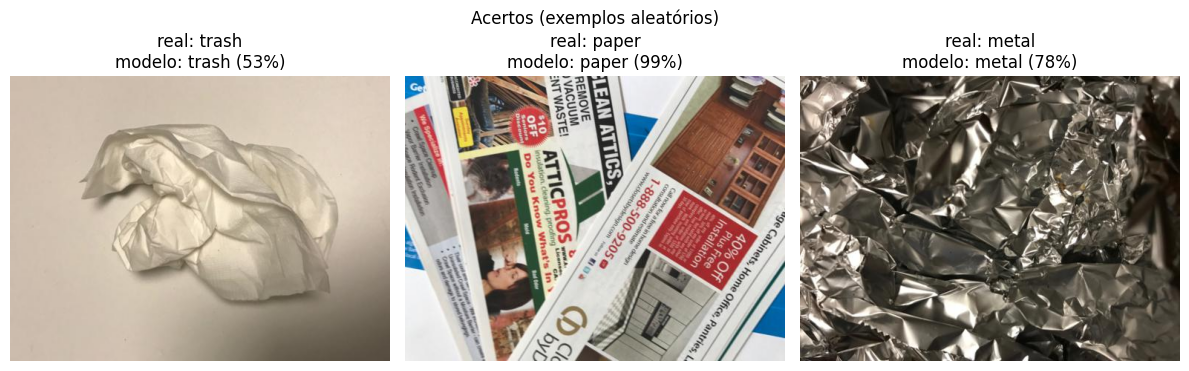

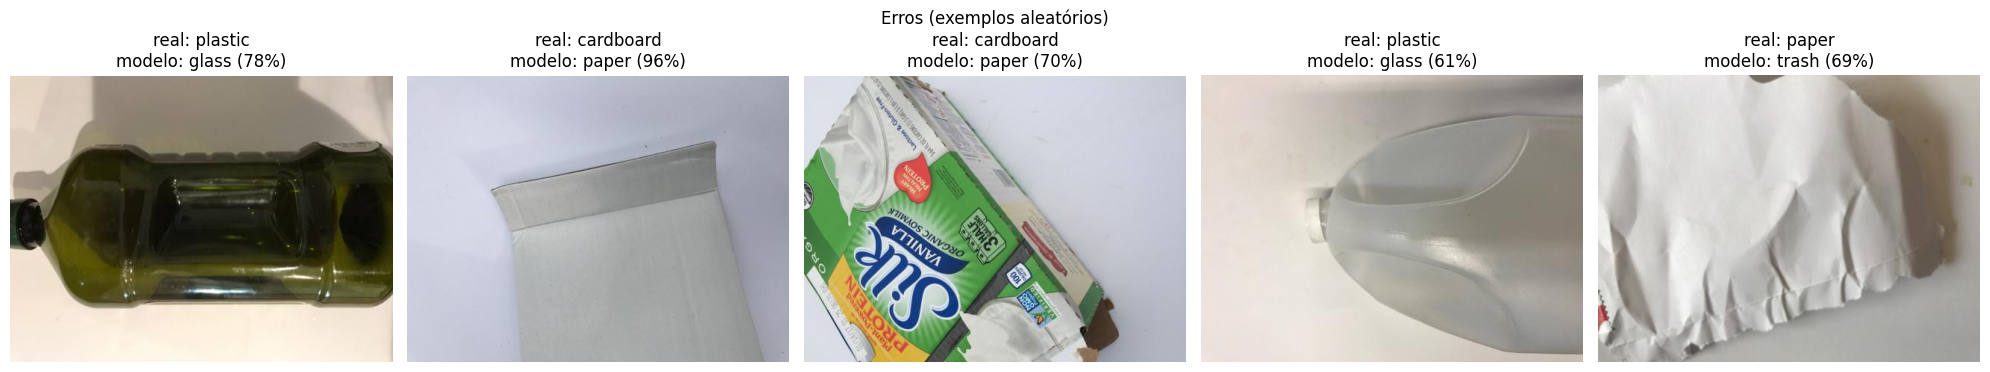


Confusões mais frequentes:
  9x: era metal, o modelo disse glass
  7x: era plastic, o modelo disse glass
  7x: era glass, o modelo disse plastic
  5x: era paper, o modelo disse cardboard
  5x: era cardboard, o modelo disse paper


In [17]:
acertos = np.where(y_pred == y_true)[0]
erros = np.where(y_pred != y_true)[0]
print(f"Acertos: {len(acertos)} | Erros: {len(erros)}")

def mostra(indices, titulo, n=5):
    indices = indices[:n]
    fig, axs = plt.subplots(1, len(indices), figsize=(4 * len(indices), 4))
    axs = np.atleast_1d(axs)
    for ax, i in zip(axs, indices):
        ax.imshow(Image.open(teste_df["caminho"].iloc[i]))
        ax.set_title(f"real: {classes[y_true[i]]}\nmodelo: {classes[y_pred[i]]} ({probs[i].max():.0%})")
        ax.axis("off")
    fig.suptitle(titulo); plt.tight_layout(); plt.show()

rng = np.random.default_rng(SEED)
mostra(rng.permutation(acertos), "Acertos (exemplos aleatórios)", n=3)
mostra(rng.permutation(erros), "Erros (exemplos aleatórios)", n=5)

# Quais confusões são mais comuns?
cm = confusion_matrix(y_true, y_pred)
np.fill_diagonal(cm, 0)
pares = sorted([(cm[i, j], classes[i], classes[j])
                for i in range(len(classes)) for j in range(len(classes)) if cm[i, j] > 0],
               reverse=True)[:5]
print("\nConfusões mais frequentes:")
for n, real, previsto in pares:
    print(f"  {n}x: era {real}, o modelo disse {previsto}")

**Análise dos erros:**
- O modelo errou 64 das 379 imagens de teste (16,9%) e acertou 315.
- Confusões mais comuns: metal virando vidro (9 vezes), plástico e vidro se confundindo (7 vezes em cada sentido), papel e papelão se confundindo (5 vezes em cada sentido).
- **Causas prováveis:** vidro, plástico e metal costumam ser brilhantes, transparentes ou reflexivos, o que gera aparências parecidas em foto. Papel e papelão têm cor e textura parecidas. Além disso, `trash` tem poucas imagens, o que provavelmente explica o F1 mais baixo.
- **PREENCHER:** escolham 1 acerto e 1 erro das imagens acima (slide 13) e descrevam: classe real, previsão do modelo, confiança e a causa provável.

## Etapa 10: Limitações e questões éticas (slide 14)

O protótipo não é uma solução pronta para uso real. Pontos para o slide:

- **Limitações dos dados:** dataset pequeno (2.524 imagens) e desbalanceado (`trash` com 137). Fotos em condições controladas, bem diferentes de um objeto sujo, amassado ou dentro de uma lixeira real.
- **Limitações do modelo:** só reconhece 6 categorias e não sabe dizer "não sei". Na demonstração, uma foto fora do padrão (pintura sobre papel amassado) ficou dividida entre papel (49,7%) e papelão (43,2%). Objetos feitos de vários materiais também confundem.
- **Possíveis vieses:** os tipos de objeto e de embalagem vêm de uma coleta específica e podem não representar os produtos brasileiros.
- **Riscos de uso:** uma classificação errada pode levar alguém a descartar um material do jeito errado ou contaminar uma carga de reciclagem. A decisão final deve ser humana.
- **Privacidade:** fotos enviadas por usuários podem conter pessoas, rostos ou ambientes pessoais ao fundo.
- **Melhorias futuras:** mais dados (inclusive brasileiros e fotos reais de celular), fine-tuning, mais augmentação e uma classe "desconhecido".

## Etapa 11: Demonstração (slide 15)

Na apresentação: execute esta célula, envie uma foto nova, mostre a previsão e **interprete** o resultado (o modelo acertou? com quanta confiança? se errou, por quê?).

**Teste já feito:** enviamos a foto de uma pintura sobre papel amassado. O modelo previu papel (49,7%) e papelão (43,2%), com metal em terceiro (3,4%). A confiança dividida mostra que ele ficou em dúvida em um caso fora do padrão do dataset, ótimo exemplo para o slide 14.

**Dicas para a demo:**
- Testem antes com fotos de celular. Se o modelo for pior que no teste, isso é um achado importante para o slide de limitações.
- Tentem um fundo simples e claro, parecido com o dos exemplos do dataset.
- Tenham 2 ou 3 fotos prontas (um acerto fácil, um caso difícil) caso a internet falhe na hora.
- O Colab perde tudo quando a sessão cai. Treinem antes da apresentação e usem a célula de salvar abaixo.

Saving pintura-no-papel-amassado-arte-pronta.webp to pintura-no-papel-amassado-arte-pronta.webp


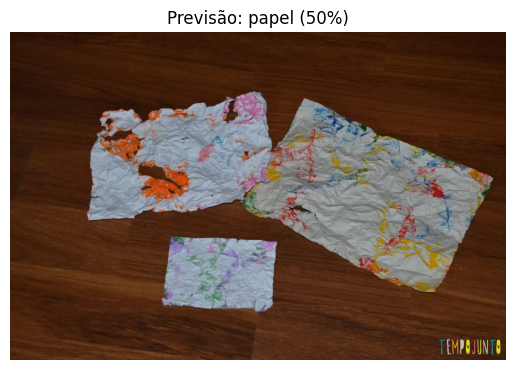

  papel: 49.7%
  papelão: 43.2%
  metal: 3.4%


In [18]:
from google.colab import files
from PIL import ImageOps

TRADUCAO = {"cardboard": "papelão", "glass": "vidro", "metal": "metal",
            "paper": "papel", "plastic": "plástico", "trash": "rejeito (lixo comum)"}

def preve_imagem(caminho):
    img = ImageOps.exif_transpose(Image.open(caminho)).convert("RGB")   # corrige foto girada do celular
    arr = tf.image.resize(np.asarray(img), (IMG, IMG)).numpy()[None, ...]
    p = modelo.predict(arr, verbose=0)[0]
    top = p.argsort()[::-1][:3]
    plt.imshow(img); plt.axis("off")
    plt.title(f"Previsão: {TRADUCAO.get(classes[top[0]], classes[top[0]])} ({p[top[0]]:.0%})")
    plt.show()
    for i in top:
        print(f"  {TRADUCAO.get(classes[i], classes[i])}: {p[i]:.1%}")

enviados = files.upload()   # clique em "Escolher arquivos" e envie uma foto
for nome in enviados:
    preve_imagem(nome)

In [ ]:
# Salva o modelo treinado (para a demo sem precisar treinar de novo).
# Depois baixe o arquivo ou salve no Google Drive, porque o Colab apaga os arquivos ao fechar.
modelo.save("modelo_lixo_reciclavel.keras")
print("Modelo salvo: modelo_lixo_reciclavel.keras")
# Para carregar depois: modelo = keras.models.load_model("modelo_lixo_reciclavel.keras")

## Conclusão (slide 15)

- **O objetivo foi alcançado?** Sim. O protótipo classifica fotos em 6 categorias com acurácia de 83,1% e F1 macro de 0,797 no teste.
- **O modelo aprendeu algo útil?** Sim, com limites. Vai bem em papel e papelão, pior em `trash`, e confunde materiais parecidos (vidro, plástico e metal).
- **A rede superou a baseline?** Sim. F1 macro de 0,797 contra 0,370.
- **Principal aprendizado do grupo:** PREENCHER (escrevam com as suas palavras).
- **O que poderia ser melhorado?** Mais dados (principalmente de `trash` e fotos brasileiras), fine-tuning, mais augmentação, uma classe "desconhecido" e testes com fotos reais de celular.